# Quantum Information

Was eine Messung an einem Quantensystem ergibt, wie man Zustände unterscheidet und wie viel Information in ihnen steckt, durchgerechnet mit numpy, scipy und semidefiniten Programmen (cvxpy): die Born-Regel aus dem Spektralsatz, allgemeine Messungen von POVMs über schwache und kontinuierliche Messung bis zu Tomographie und Classical Shadows, und die Quanteninformationstheorie mit Abstandsmaßen, Entropien, Holevo-Schranke, No-Cloning, Fisher-Information und Kanalkapazitäten. Daten werden nicht geladen. Der Code steht in [`code/quantum_information/`](https://github.com/deltorobarba/science/tree/main/code/quantum_information), ein Modul je Teil (`born.py`, `measurement.py`, `information.py`); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Die drei Teile bauen aufeinander auf: Erst wird geklärt, was eine Messung ist, dann was sie leisten kann, dann was man aus Quantenzuständen an Information herausholen kann.

- **Schritte 1 bis 6, Born-Regel:** Eigenwerte sind Messwerte, Projektoren geben Wahrscheinlichkeiten und den Zustand danach. Häufigkeiten nähern sich den Wahrscheinlichkeiten wie 1/√N.
- **Schritte 7 bis 20, Quantenmessung:** POVMs verallgemeinern die projektive Messung. Information kostet Kohärenz, der Kollaps wird bei schwacher Messung zum Zufallsweg, und Tomographie, Benchmarking und Classical Shadows charakterisieren Zustände und Gatter.
- **Schritte 21 bis 31, Quanteninformation:** Abstandsmaße sagen, wie gut man Zustände unterscheiden kann, Entropien zählen Ressourcen, und No-Cloning, Holevo-Schranke und Kapazitäten setzen die Grenzen.

Die gemeinsame Lehre: Jede Messung ist ein Tausch. Wer mehr erfährt, stört mehr, und keine Messung holt mehr heraus, als die Holevo-Schranke erlaubt.

In [1]:
import sys
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "quantum_information"
if "google.colab" in sys.modules and not CODE.exists():      # in Colab den Code aus dem Repository holen
    CODE.mkdir(parents=True)
    for f in ["born.py", "measurement.py", "information.py"]:
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/quantum_information/{f}", CODE / f)
if "google.colab" not in sys.modules and (importlib.util.find_spec("cvxpy") is None):
    raise ImportError("Es fehlt eines der Pakete cvxpy; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import born, measurement, information

**1. Born-Regel: der Spektralsatz**

Die Quantenmechanik sagt für ein einzelnes Messergebnis nur Wahrscheinlichkeiten voraus; Max Born las 1926 das Betragsquadrat der Wellenfunktion als Wahrscheinlichkeit. Heute steht die Regel neben dem Spektralsatz: Eine Observable ist eine selbstadjungierte Matrix, ihre Eigenwerte sind die möglichen Messwerte, und die Projektoren auf die Eigenräume bestimmen die Wahrscheinlichkeiten und den Zustand danach (Lüders 1951). Als erstes wird eine Matrix mit einem doppelten Eigenwert in Eigenwerte und Projektoren zerlegt.

Die Eigenwerte sind 1 und 3; der doppelte Eigenwert 3 bekommt einen Projektor auf eine ganze Ebene (Rang 2). Alle drei Prüfungen gelingen: A = 1·P₁ + 3·P₃, die Projektoren summieren sich zur Einheitsmatrix und stehen senkrecht aufeinander.

In [2]:
born.spectral_theorem()

Eigenwerte:         [1. 3.]
A = Σ a_k P_k:      True
Σ P_k = I:          True
P_k P_l = 0 (k≠l):  True
Rang der P_k:       [1, 2]


**2. Häufigkeit gegen Anzahl der Messungen**

Ein Qubit wird 10 000-mal in der Basis von σ_z gemessen. Die laufende Häufigkeit von +1 wird mit der Born-Wahrscheinlichkeit p(+1) = cos²(θ/2) = 0.25 verglichen, mit dem Band einer Standardabweichung √(p(1−p)/N).

Am Anfang springt die Häufigkeit stark, ab einigen hundert Messungen bleibt sie im Band, das sich wie 1/√N zusammenzieht. Nach 10 000 Messungen ist sie 0.2442, 1.4 Standardabweichungen neben 0.25: Wahrscheinlichkeiten zeigen sich erst in vielen Wiederholungen.

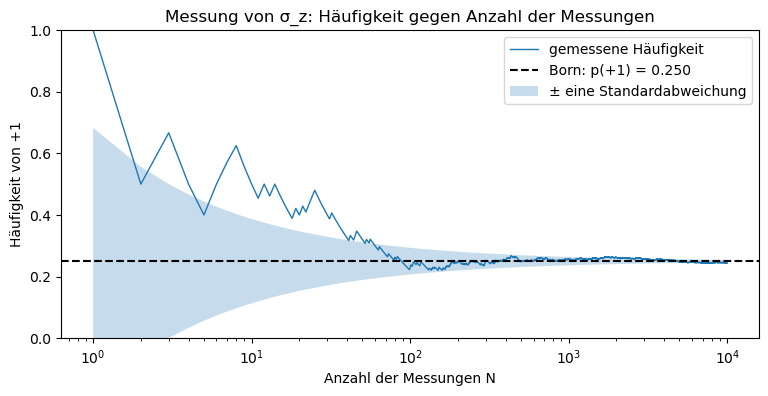

p(+1) = 0.2500; nach N = 10000: Häufigkeit 0.2442, Abweichung 0.0058, eine Standardabweichung 0.0043
Anteil der N, bei denen die laufende Häufigkeit im Band ±σ liegt: 0.65


In [3]:
born.frequencies()

**3. Verteilung der Häufigkeit bei festem N**

Derselbe Zustand in 5000 Serien zu je 100 Messungen; jede Serie gibt eine Häufigkeit von +1.

Das Histogramm liegt auf der Normalverteilung mit Mittel 0.25 und Breite 0.043; schon bei 100 Messungen ist die Binomialverteilung kaum davon zu unterscheiden (zentraler Grenzwertsatz). Eine Serie von 100 Messungen bestimmt p also nur auf ±0.04; für eine Stelle mehr braucht man hundertmal so viele.

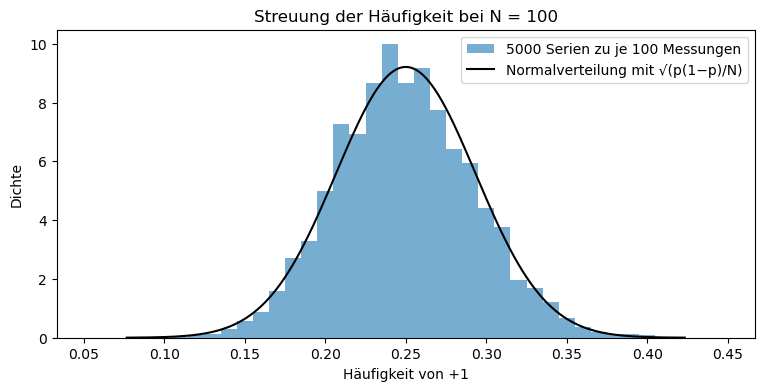

gemessene Standardabweichung 0.0430, vorhergesagt 0.0433


In [4]:
born.frequency_distribution()

**4. Messrichtung auf der Bloch-Kugel**

Ein Qubit-Zustand ist ein Punkt r auf der Bloch-Kugel, eine Messrichtung ein Einheitsvektor n; die Born-Regel wird dann p(±) = ½(1 ± n·r). Derselbe Zustand wird in 13 Richtungen vom Nord- zum Südpol gemessen.

Die Häufigkeiten folgen einer verschobenen Kosinuskurve mit dem Maximum bei 120°. Das Maximum ist 0.970 und nicht 1, weil der Bloch-Vektor mit einem Teil aus der Messebene herauszeigt. Die größte Abweichung von der Kurve beträgt 2.4 Standardabweichungen.

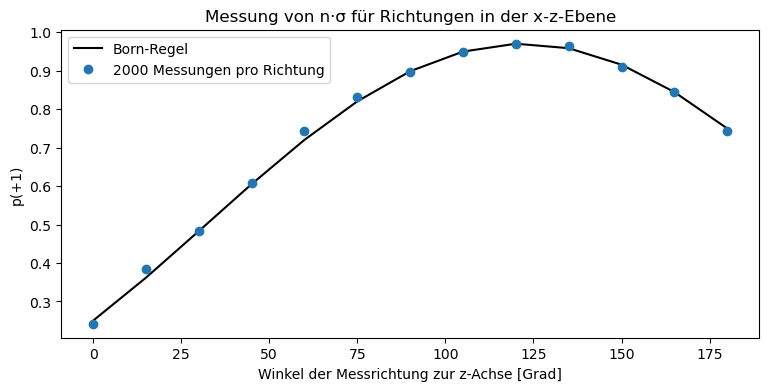

Bloch-Vektor r = [ 0.798  0.337 -0.5  ]; p(+1) von 0.250 bis 0.970
größte Abweichung Messung gegen Born-Regel: 0.024 bei 60°
in Standardabweichungen: größter Wert 2.4 bei 60°, Mittelwert 0.82


In [5]:
born.bloch_direction()

**5. Zustand nach der Messung**

Nach der Lüders-Regel ist das System nach dem Ergebnis im zugehörigen Eigenraum. Zwei Folgen von Messungen: zweimal σ_z, und σ_z, dann σ_x, dann wieder σ_z.

Zweimal σ_z gibt in allen 1000 Fällen dasselbe Ergebnis: Messungen sind wiederholbar. Mit σ_x dazwischen stimmen erstes und letztes Ergebnis nur in 495 von 1000 Fällen überein, etwa der Hälfte: Die Messung von σ_x hat die Information der ersten Messung gelöscht.

In [6]:
born.post_measurement()

(a) σ_z, dann σ_z:          gleiches Ergebnis in 1000 von 1000 Fällen
(b) σ_z, dann σ_x, dann σ_z: gleiches Ergebnis in 495 von 1000 Fällen


**6. Entartete Eigenwerte**

Der Zustand nach einer Messung, deren Ergebnis niemand liest, für eine Observable mit doppeltem Eigenwert und für eine feinere, die alle Basiszustände unterscheidet.

Mit der entarteten Observablen bleibt die Kohärenz zwischen |0⟩ und |1⟩ (0.333) erhalten, weil beide im selben Eigenraum liegen; gelöscht werden nur die Kohärenzen zu |2⟩. Die feinere Observable löscht auch sie. Eine Messung zerstört genau die Kohärenzen zwischen Zuständen, die sie unterscheidet.

In [7]:
born.degenerate()

A = diag(1, 1, -1), entartet  : Element <0|rho|1> vorher 0.333, nachher 0.333
B = diag(1, 2, -1), verfeinert: Element <0|rho|1> vorher 0.333, nachher 0.000


**7. Quantenmessung: POVMs und Naimark-Dilatation**

Die projektive Messung ist nicht die allgemeinste. Eine Messung beschreibt man allgemein mit positiven Operatoren E_k, die sich zur Einheit summieren (POVM); ihre Elemente müssen keine Projektoren sein, und es kann mehr Ergebnisse geben als Dimensionen. Naimark zeigte, dass jede POVM eine projektive Messung an einem größeren System ist. Gezeigt werden zwei Beispiele, die Trine mit drei Ergebnissen und die SIC mit vier, die als Tetraeder in der Bloch-Kugel liegt.

Beide sind gültige POVMs; ein Trine-Element hat die Eigenwerte 0 und 0.667, also Rang 1, ist aber kein Projektor. Die vier SIC-Elemente sind linear unabhängig und bestimmen damit jeden Zustand vollständig. Die Wahrscheinlichkeiten aus der POVM und die Häufigkeiten aus 20 000 projektiven Messungen am größeren System nach Naimark stimmen überein.

Trine ist ein POVM: True | SIC ist ein POVM: True
Eigenwerte eines Trine-Elements: [0.    0.667] -> Rang 1, aber kein Projektor
SIC informationell vollständig (4 linear unabhängige Elemente): True
Trine: U ist 6x6 und unitär: True | Tr(E_m ρ) = [0.4845 0.4545 0.061 ] | Naimark = [0.4845 0.4545 0.061 ]
SIC: U ist 8x8 und unitär: True | Tr(E_m ρ) = [0.3634 0.3729 0.2491 0.0147] | Naimark = [0.3634 0.3729 0.2491 0.0147]


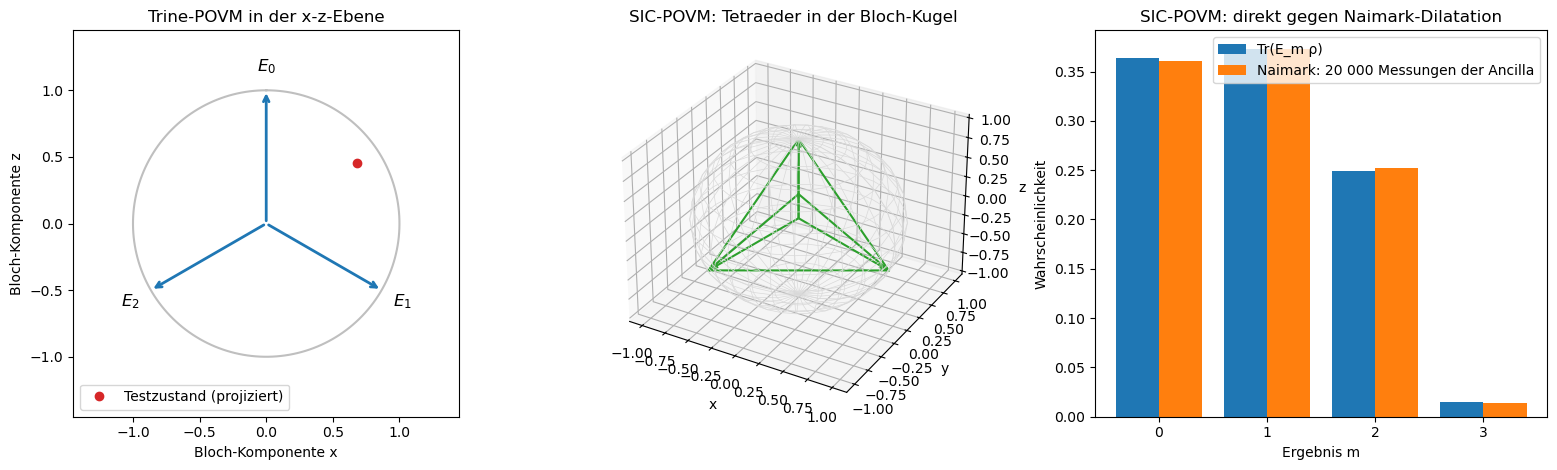

In [8]:
measurement.povm()

**8. Das Zeigermodell: von stark zu schwach**

Von Neumann beschrieb eine Messung als Kopplung des Systems an einen Zeiger mit Unschärfe σ. Die Kopplungsstärke g regelt, wie viel man erfährt und wie stark der Zustand gestört wird.

Bei g/σ = 3 zerfällt die Zeigerverteilung in zwei getrennte Glocken: eine projektive Messung. Bei g/σ = 0.2 ist es fast eine einzige Glocke, ein einzelnes Ablesen verrät kaum etwas. Information und verbleibende Kohärenz kreuzen sich: Mehr Information heißt immer weniger Kohärenz.

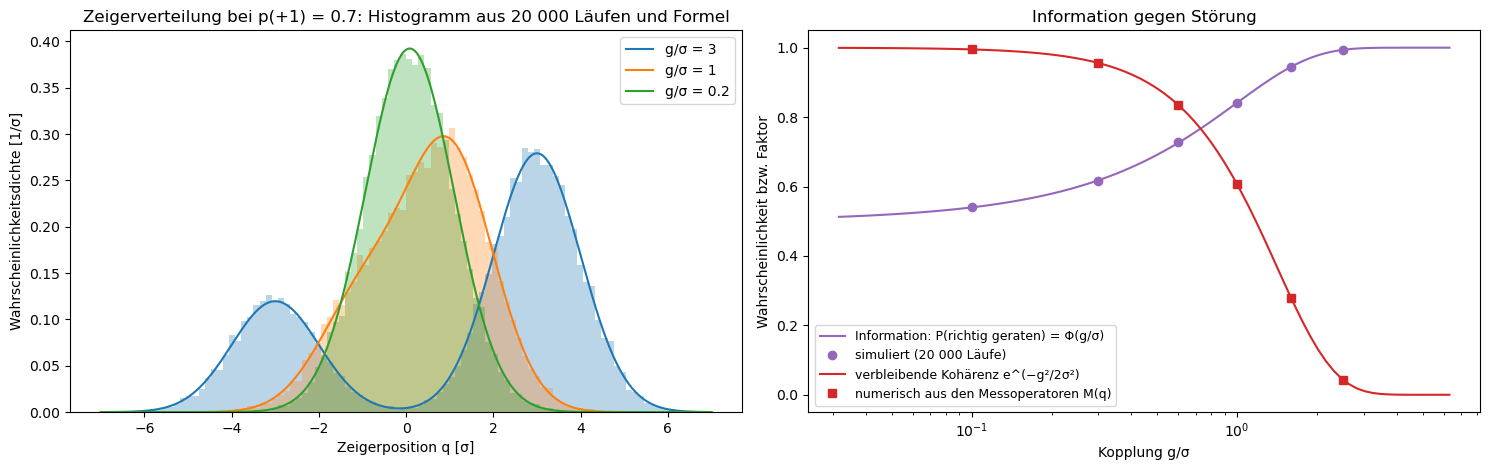

In [9]:
measurement.pointer_model()

**9. Zwei Zustände unterscheiden**

Zwei Zustände mit Überlapp c lassen sich nie sicher unterscheiden. Die beste Messung (Helstrom) minimiert den Fehler; die eindeutige Unterscheidung irrt nie, sagt aber manchmal „?“.

Für kleine c macht die naive Messung doppelt so viele Fehler wie Helstrom; bei c = 0.6 ist der Helstrom-Fehler 0.10. Die eindeutige Messung irrt sich in keinem Lauf, sagt aber bei c = 0.6 in 60 % der Fälle „?“, genau c.

c = 0.20: Helstrom-Fehler 0.0103 (Formel 0.0101) | eindeutig: Fehler 0.0000, „?“ 0.2050 (Formel 0.20) | E_? ≥ 0: True
c = 0.40: Helstrom-Fehler 0.0421 (Formel 0.0417) | eindeutig: Fehler 0.0000, „?“ 0.4029 (Formel 0.40) | E_? ≥ 0: True
c = 0.60: Helstrom-Fehler 0.1007 (Formel 0.1000) | eindeutig: Fehler 0.0000, „?“ 0.5988 (Formel 0.60) | E_? ≥ 0: True
c = 0.80: Helstrom-Fehler 0.2001 (Formel 0.2000) | eindeutig: Fehler 0.0000, „?“ 0.7996 (Formel 0.80) | E_? ≥ 0: True
c = 0.95: Helstrom-Fehler 0.3426 (Formel 0.3439) | eindeutig: Fehler 0.0000, „?“ 0.9539 (Formel 0.95) | E_? ≥ 0: True


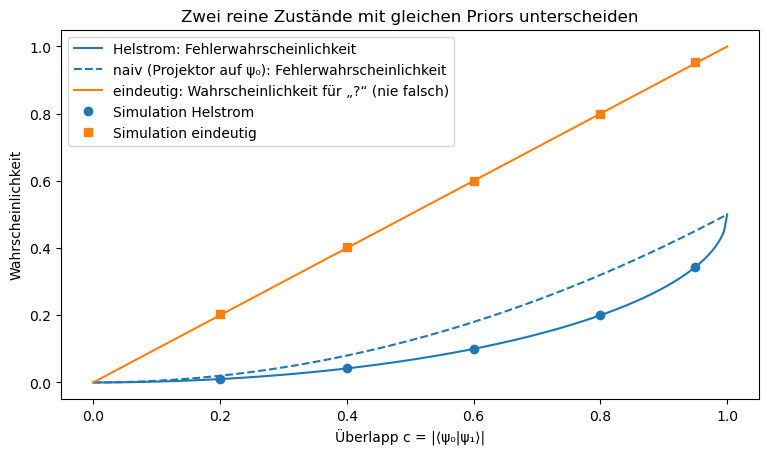

In [10]:
measurement.two_states()

**10. Drei Zustände: SDP gegen Pretty-Good-Measurement**

Für drei Zustände gibt es keine Formel; die beste Messung ist die Lösung eines semidefiniten Programms (SDP, mit cvxpy). Verglichen wird mit der einfachen Pretty-Good-Measurement (PGM) für Zustände mit wachsendem Winkel.

Bei kleinem Winkel liegen beide kaum über dem Raten (⅓). Ab etwa 85° erreicht die beste Messung ⅔, die Obergrenze für drei reine Qubit-Zustände; die PGM erreicht das Optimum erst bei der symmetrischen Trine (120°), wo beide 0.667 geben.

Trine (β = 120°): SDP 0.6667, PGM 0.6667, erwartet 2/3
PGM ≥ SDP² überall: True
Zufällige gemischte Zustände, Priors [0.5, 0.3, 0.2]: SDP 0.6201, PGM 0.5388


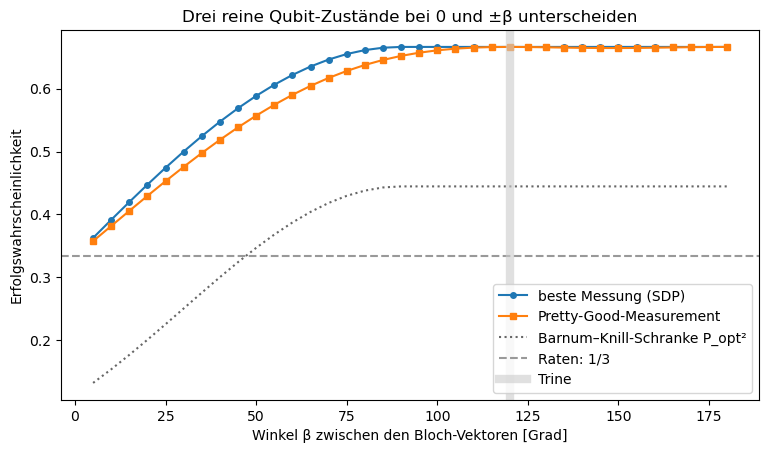

In [11]:
measurement.three_states()

**11. Unschärfe und gemeinsame Messbarkeit**

Drei Blicke auf die Unschärfe: das Produkt der Streuungen von X und Z gegen die Schranke von Robertson und Schrödinger, die Summe der Entropien, und wie scharf zwei verwaschene Messungen sein dürfen, um gemeinsam messbar zu sein.

Die Robertson-Schranke ist in der x-z-Ebene null und sagt nichts; die Entropiesumme bleibt immer über 1 Bit. Für reine Zustände ist die Schrödinger-Relation eine Gleichung. Zwei verwaschene Messungen von X und Z sind genau dann gemeinsam messbar, wenn die Quadrate ihrer Schärfen zusammen höchstens 1 ergeben.

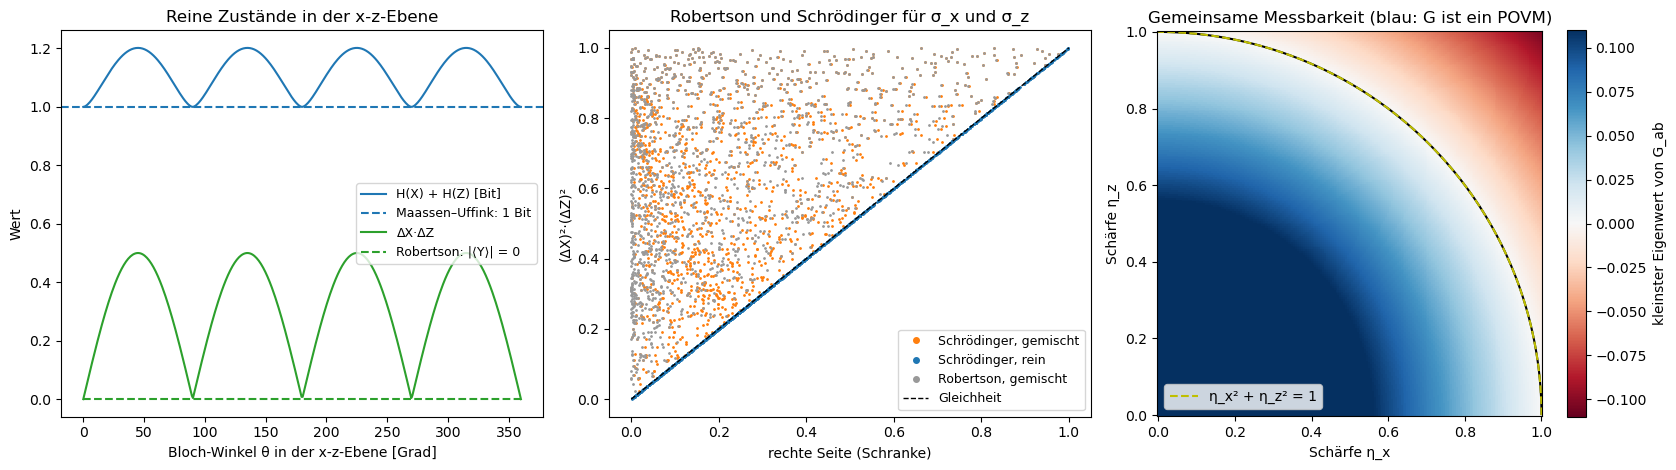

Minimum von H(X) + H(Z) auf dem Kreis: 1.0000 Bit


In [12]:
measurement.uncertainty()

**12. Schwache Messung und Weak Value**

Mit schwacher Kopplung messen und danach nur die Läufe behalten, die in einem bestimmten Endzustand landen (Postselektion). Der Zeiger zeigt dann den Weak Value, der weit außerhalb der Eigenwerte liegen kann.

Bei schwacher Kopplung ist der Zeiger um etwa das Zehnfache dessen verschoben, was ein Eigenwert ±1 ergäbe: Der Weak Value ist 9.97. Mit stärkerer Kopplung kehrt die Verschiebung ins Spektrum zurück. Der Preis ist, dass die Postselektion nur selten gelingt.

Weak Value A_w = 9.967 (cot ε = 9.967), Wahrscheinlichkeit der Postselektion 0.0100


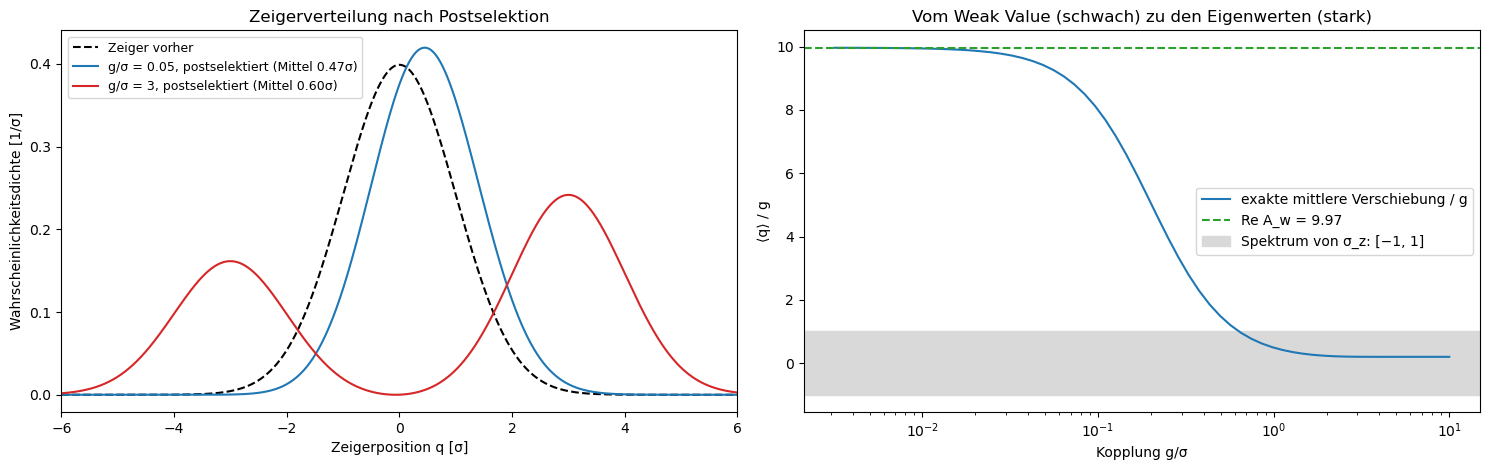

nötig: etwa 101 postselektierte Läufe, also etwa 10101 Läufe insgesamt


In [13]:
measurement.weak_value()

**13. Kontinuierliche Messung: der Kollaps als Zufallsweg**

Bei einer schwachen, andauernden Messung wandert der Zustand zufällig; beschrieben wird das mit einer stochastischen Mastergleichung. 1000 Läufe starten mit p(+1) = 0.7.

Jede Trajektorie läuft zufällig an +1 oder −1, wo das Rauschen verschwindet; der Kollaps ist kein Sprung, sondern ein Zufallsweg. 69.7 % enden bei +1, wie es die Born-Regel verlangt. Im Mittel bleibt z konstant, und die Kohärenz fällt ab: Born-Regel und Dephasierung kommen aus derselben Gleichung.

Anteil der Läufe bei z = +1: 0.697 (Born: 0.70); |z| > 0.99 am Ende: 1.000


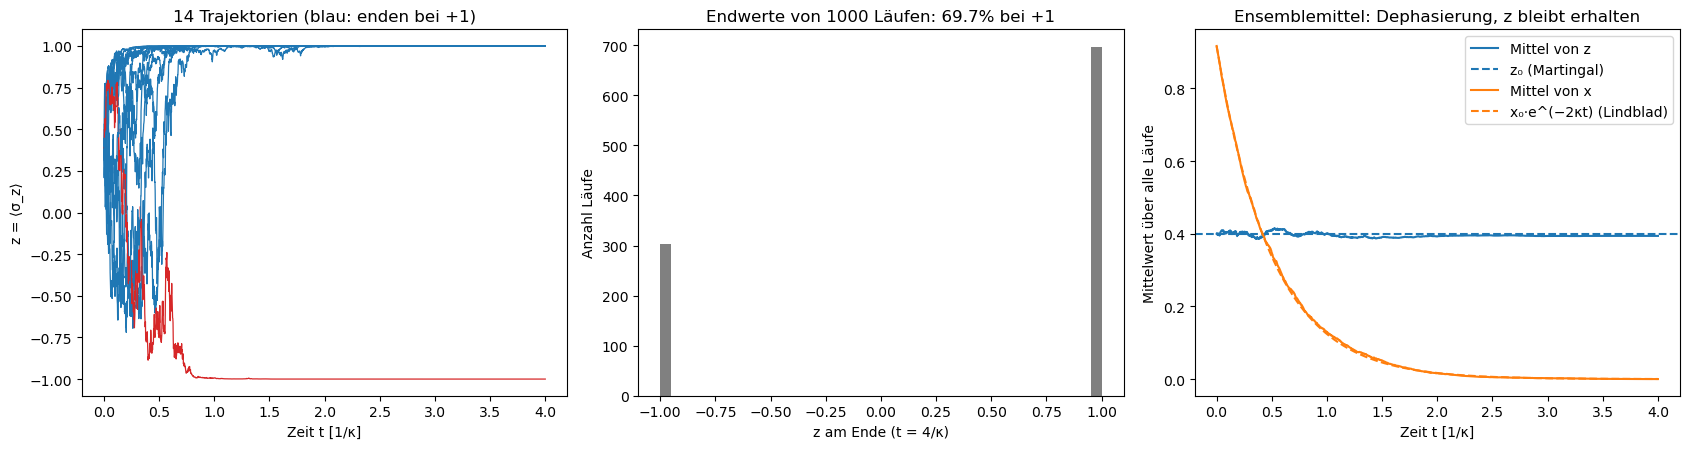

In [14]:
measurement.continuous()

**14. Eine Mastergleichung, zwei Arten von Trajektorien**

Ein angeregtes Qubit zerfällt; beobachtet wird es einmal mit einem Photodetektor (Klicks) und einmal mit Homodyn-Detektion (eine Feldquadratur).

Mit Photodetektion springt jede Trajektorie beim Klick nach unten; auch das Ausbleiben eines Klicks ist Information. Mit Homodyn-Detektion diffundieren die Trajektorien stetig. Beide Mittelwerte liegen auf derselben Lösung der Lindblad-Gleichung: Wie der Einzelfall aussieht, hängt davon ab, was man misst.

Anteil der Läufe mit Klick bis t = 5/γ: 0.488 (erwartet ½(1 − e^(−γT)) = 0.497)


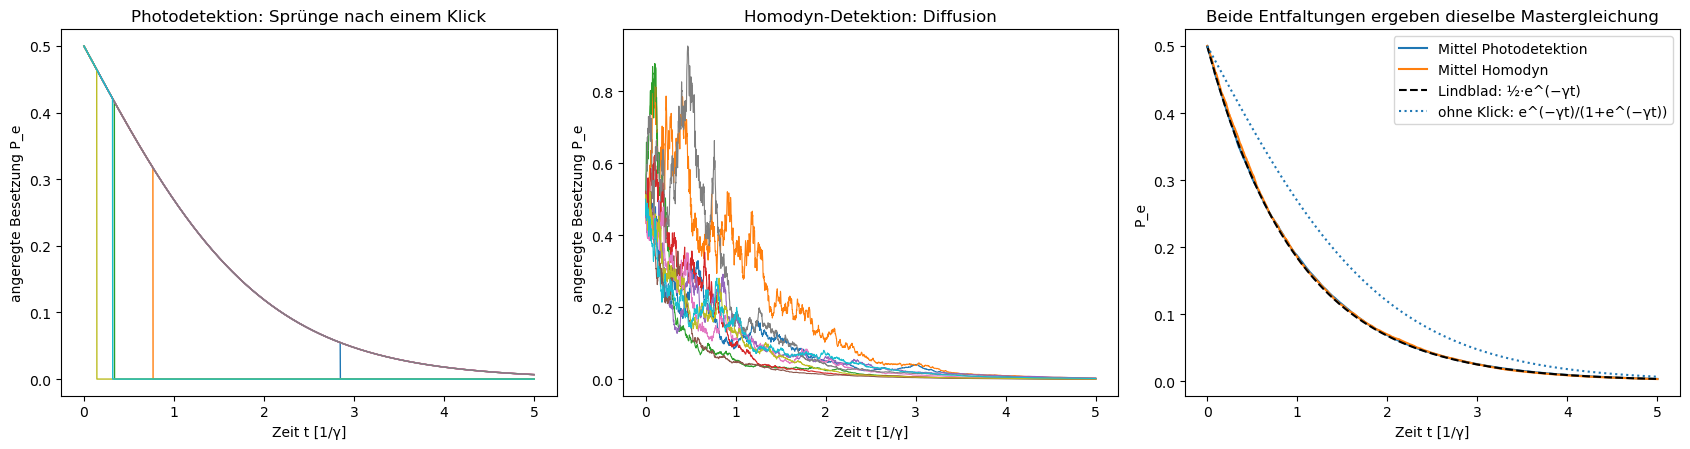

In [15]:
measurement.trajectories()

**15. Quanten-Zeno-Effekt**

Ein Antrieb dreht |0⟩ in die Richtung von |1⟩; dazwischen wird oft gemessen, projektiv oder kontinuierlich.

Ohne Zwischenmessung wird das Qubit vollständig gedreht, mit 40 Messungen bleibt es mit Wahrscheinlichkeit 0.94 in |0⟩. Bei kontinuierlicher Messung wird der Übergang umso langsamer, je stärker gemessen wird, mit der Rate Ω²/2κ: Häufiges Hinsehen friert die Entwicklung ein.

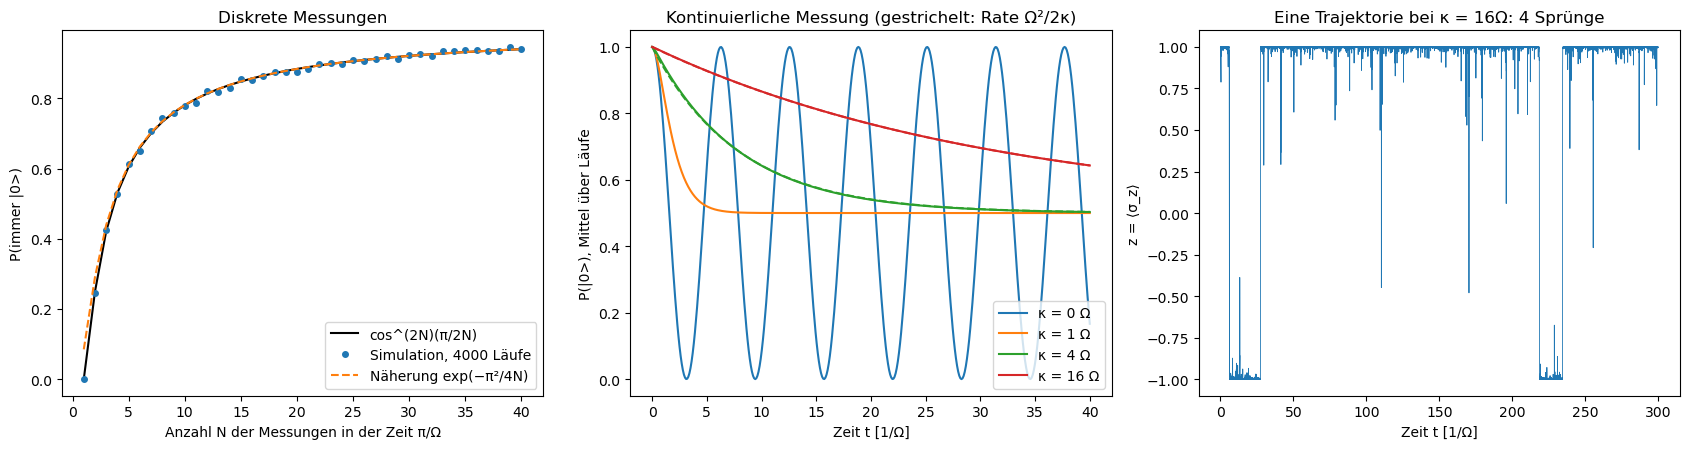

Sprünge in t = 300/Ω: 4; erwartet im Mittel 300·Ω²/(4κ) = 4.7 (Sprungrate in jede Richtung Ω²/4κ, Anzahl Poisson-verteilt)


In [16]:
measurement.zeno()

**16. Feedback: den Zufall des Kollapses beseitigen**

Kontinuierliche Messung von σ_z, und das Messsignal steuert sofort eine Drehung, die den Zustand nach +1 schiebt.

Ohne Rückkopplung enden die Läufe zufällig, je zur Hälfte bei +1 und −1. Ab der Schwelle λ = 4κ enden fast alle bei +1, ab 6κ alle 400. Der Zufall des Kollapses lässt sich mit dem Messsignal selbst beseitigen.

λ = 0κ: Anteil bei +1 = 0.512
λ = 0.5κ: Anteil bei +1 = 0.593
λ = 1κ: Anteil bei +1 = 0.667
λ = 2κ: Anteil bei +1 = 0.835
λ = 3κ: Anteil bei +1 = 0.927
λ = 4κ: Anteil bei +1 = 0.988
λ = 6κ: Anteil bei +1 = 1.000
λ = 8κ: Anteil bei +1 = 1.000


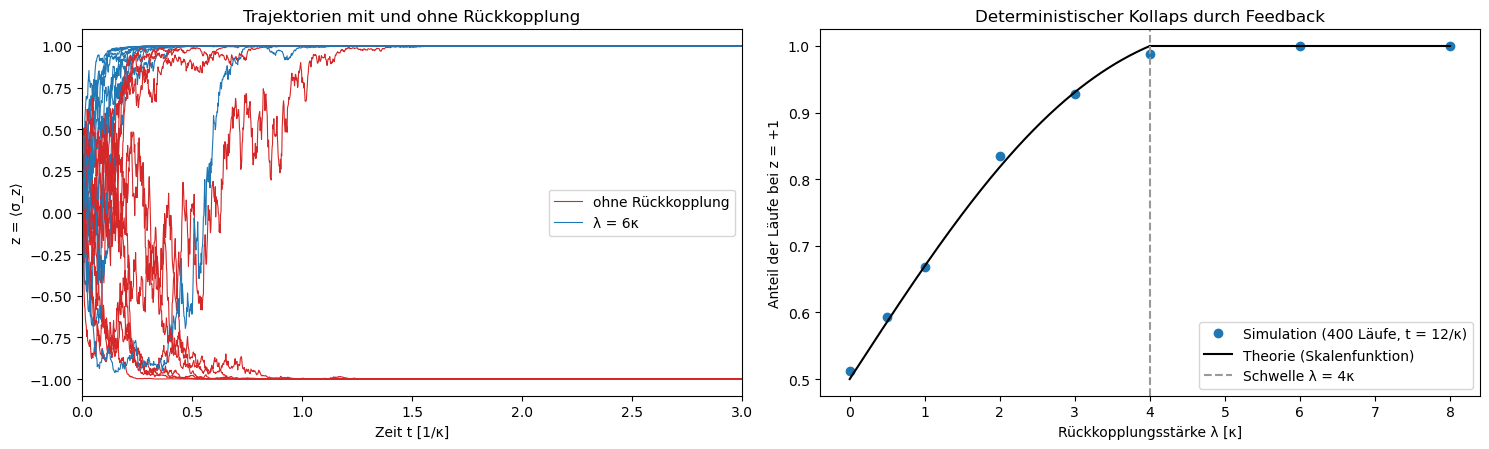

In [17]:
measurement.feedback()

**17. Zustandstomographie**

Ein unbekannter Zustand wird aus Messungen in drei Basen rekonstruiert, mit linearer Inversion (LI) und mit Maximum-Likelihood (MLE), für 10 bis 10 000 Messungen je Basis.

Beide Fehler fallen wie 1/√N; MLE ist bei wenigen Messungen gut doppelt so genau (0.17 gegen 0.37). Die lineare Inversion liefert oft unphysikalische Zustände mit negativem Eigenwert: bis N = 300 in allen 20 Fällen, bei 10 000 noch in einem. Der wahre Zustand ist fast rein, und schon kleines Rauschen schiebt seine winzigen Eigenwerte unter null.

N =    10: Spurabstand LI 0.3744, MLE 0.1693, LI unphysikalisch in 20/20 Fällen
N =    30: Spurabstand LI 0.2236, MLE 0.1263, LI unphysikalisch in 20/20 Fällen
N =   100: Spurabstand LI 0.1167, MLE 0.0751, LI unphysikalisch in 20/20 Fällen
N =   300: Spurabstand LI 0.0736, MLE 0.0503, LI unphysikalisch in 20/20 Fällen


N =  1000: Spurabstand LI 0.0360, MLE 0.0284, LI unphysikalisch in 16/20 Fällen
N =  3000: Spurabstand LI 0.0247, MLE 0.0222, LI unphysikalisch in 8/20 Fällen
N = 10000: Spurabstand LI 0.0116, MLE 0.0111, LI unphysikalisch in 1/20 Fällen


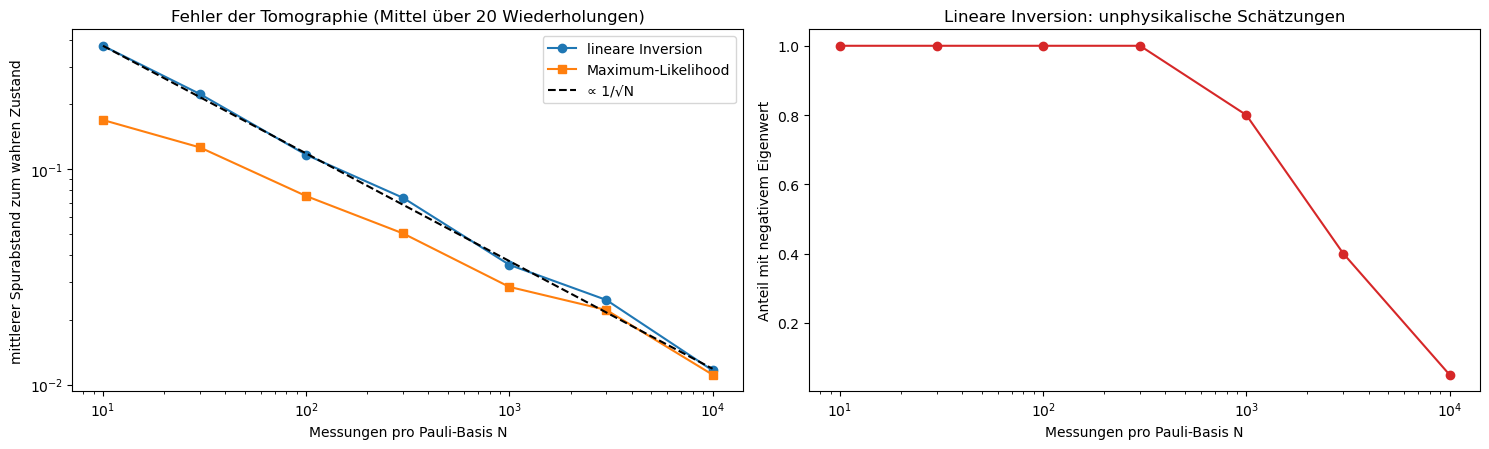

In [18]:
measurement.state_tomography()

**18. Prozesstomographie der Amplitudendämpfung**

Vier Eingangszustände laufen durch einen Kanal, der Energie verliert; aus ihren Ausgängen folgt die Pauli-Transfermatrix des Kanals, einmal mit idealer Präparation und Auslese, einmal mit Fehlern darin (SPAM).

Ohne SPAM-Fehler trifft die Rekonstruktion die wahre Matrix auf 0.017, das statistische Rauschen. Mit 4 % Präparations- und 3 % Auslesefehler weicht sie um 0.094 ab, als wäre der Kanal selbst verrauschter: Prozesstomographie schreibt SPAM-Fehler dem Kanal zu.

wahre PTM:
 [[1.    0.    0.    0.   ]
 [0.    0.837 0.    0.   ]
 [0.    0.    0.837 0.   ]
 [0.3   0.    0.    0.7  ]]
größte Abweichung: ohne SPAM 0.017, mit SPAM-Fehlern 0.094


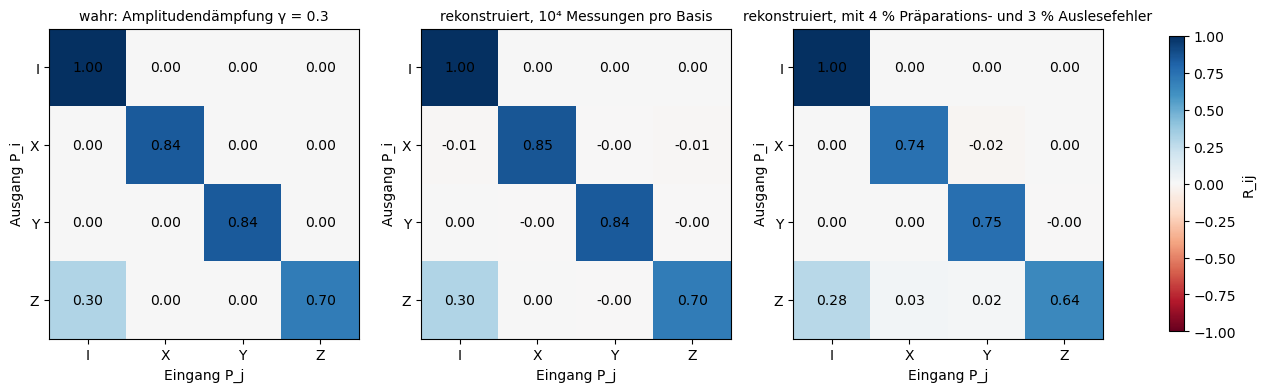

In [19]:
measurement.process_tomography()

**19. Randomized Benchmarking**

Zufällige Folgen von Clifford-Gattern, deren Produkt die Identität ist; wie oft der Anfangszustand überlebt, fällt mit der Folgenlänge exponentiell ab.

Der Fit gibt eine Fehlerrate pro Gatter von 0.00400 ± 0.00005, gegen den wahren Wert 0.00399, obwohl Präparation und Auslese fehlerhaft sind: Die SPAM-Fehler stecken nur in Vorfaktor und Grundlinie. RB sieht allerdings nur die mittlere Fidelity, nicht, ob ein Fehler kohärent ist.

Anzahl Clifford-Gatter: 24


Fit: A = 0.433, p = 0.99200, B = 0.518
Fehlerrate pro Gatter: RB 0.00400 ± 0.00005 (Fit-Unsicherheit), wahr 0.00399


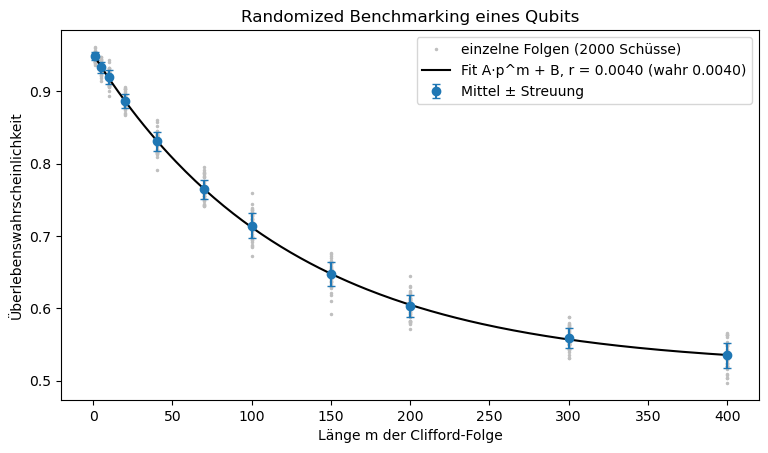

In [20]:
measurement.benchmarking()

**20. Classical Shadows**

Jeder Schnappschuss misst jedes Qubit in einer zufälligen Pauli-Basis. Aus denselben Schnappschüssen lassen sich viele Erwartungswerte zugleich schätzen; die Varianz wächst wie 3^k mit der Zahl k der Qubits, auf die eine Observable wirkt.

Alle Fehler fallen wie 1/√N, und ihre Höhe wächst mit k: Für sechs Qubits ist der Fehler gut neunmal größer als für zwei. Ein Datensatz aus 30 000 Schnappschüssen schätzt alle 135 Paar-Observablen zugleich, im Mittel auf 0.015.

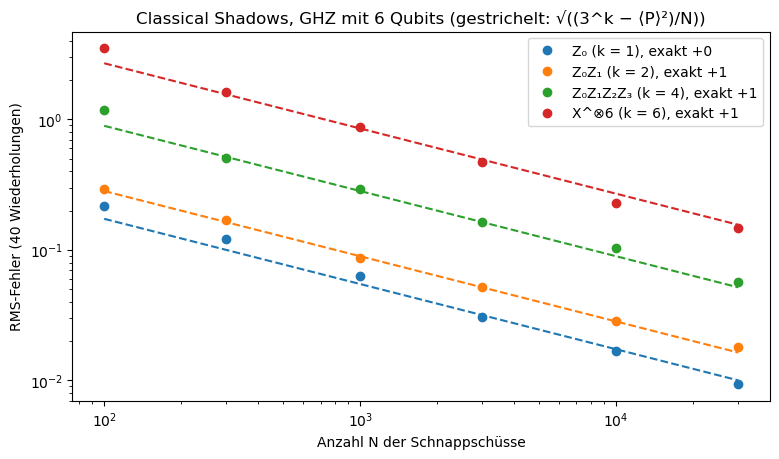

Aus 30 000 Schnappschüssen: größter Fehler über alle 135 zwei-lokalen Pauli-Strings 0.052, mittlerer 0.015


In [21]:
measurement.shadows()

**21. Quanteninformation: Abstandsmaße für ein Qubit**

Ein Abstandsmaß ist nur so gut wie die Aufgabe, die es beschreibt. Der Spurabstand sagt, wie gut man zwei Zustände mit einer Messung unterscheiden kann, die Fidelity, wie stark sie sich überlappen, die relative Entropie, wie schnell der Fehler mit der Zahl der Kopien fällt. Entropien zählen Ressourcen: Qubits für die Kompression, Bits, die man auslesen kann, Kapazitäten von Kanälen. Zuerst werden die Abstandsmaße an Qubits verglichen und am klassischen Grenzfall geprüft.

Für diagonale Zustände sind die Quantenmaße auf sechs Stellen gleich ihren klassischen Vorbildern (Totalvariation, Bhattacharyya, Kullback-Leibler). Für reine Zustände liegen Spurabstand und √(1 − F) genau aufeinander; der Hilbert-Schmidt-Abstand liegt darüber.

Spurabstand 0.447149  | TV-Abstand 0.447149
Fidelity    0.679530  | (Σ√(pq))²  0.679530
D(ρ||σ)     1.511642  | KL         1.511642


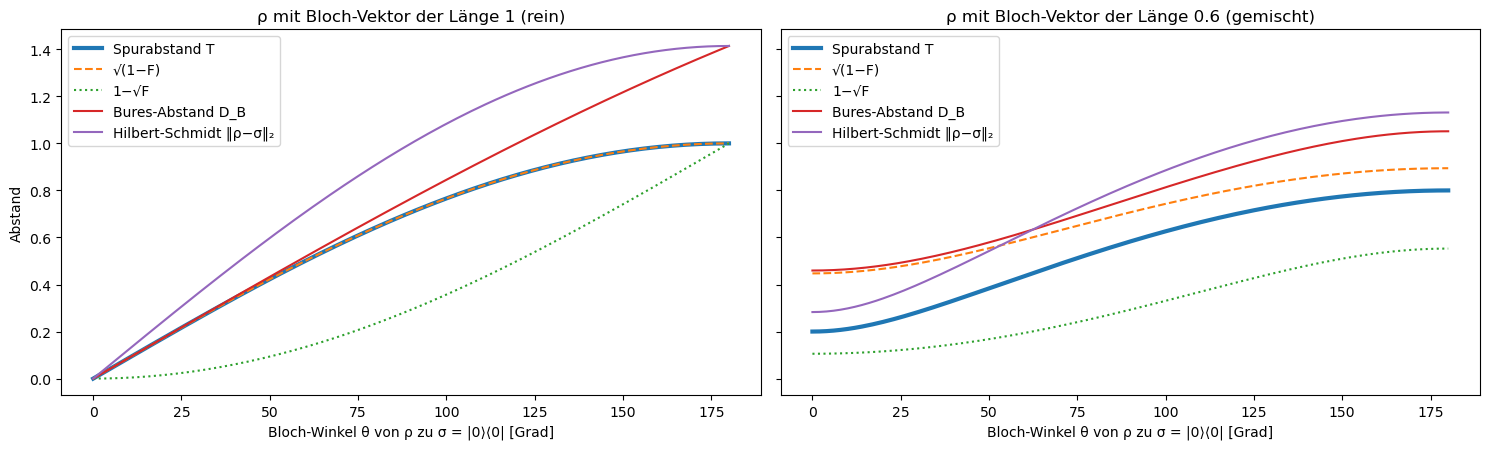

Qubit-Formel: T = 0.421793, ½|r − s| = 0.421793


In [22]:
information.qubit_distances()

**22. Fuchs-van de Graaf und Pinsker**

Zwei Ungleichungen verbinden die Maße: Der Spurabstand liegt zwischen 1 − √F und √(1 − F) (Fuchs-van de Graaf), und die relative Entropie ist mindestens 2T²/ln 2 (Pinsker). Geprüft an 3000 zufälligen Paaren.

Alle Punkte liegen im erlaubten Streifen, reine Paare genau auf der oberen Grenze. Die Pinsker-Schranke ist fast scharf (kleinster Abstand 0.0007 Bit). Für kleine Abstände bestimmen Spurabstand, Fidelity und relative Entropie einander gut.

1 − √F ≤ T ≤ √(1−F) für alle Paare: True
reine Paare: größte Abweichung von T = √(1−F): 3.1e-15
Pinsker: kleinstes D − 2T²/ln2 = 0.0007 (≥ 0)


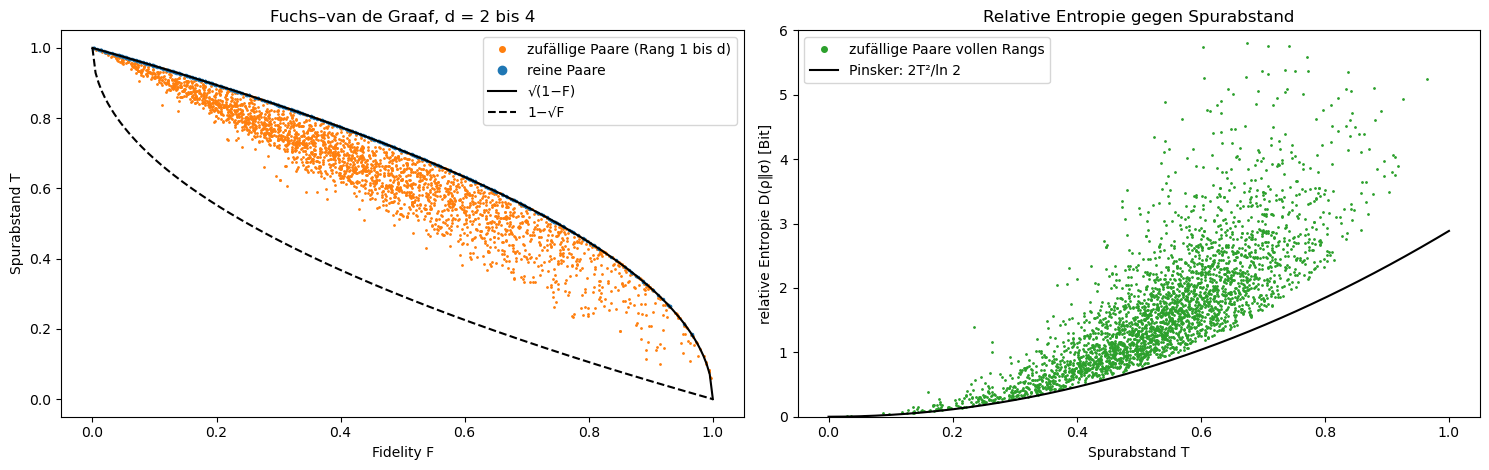

In [23]:
information.fvdg_pinsker()

**23. Datenverarbeitung: Kanäle machen Zustände nie unterscheidbarer**

Jeder Abstand wird vor und nach einem zufälligen Kanal berechnet. Ein gutes Maß darf durch Verarbeitung nie wachsen.

Spurabstand, Bures-Abstand und relative Entropie fallen in allen 3000 Fällen. Der Hilbert-Schmidt-Abstand wächst in 0.2 % der Fälle, bis zum Faktor 1.17; schon das Weglassen eines Hilfssystems kann ihn um √d vergrößern. Er ist bequem zu rechnen, aber kein Maß für Unterscheidbarkeit.

Spurabstand       : größtes Verhältnis 0.9819, Anteil > 1: 0.000
Bures-Abstand     : größtes Verhältnis 0.9729, Anteil > 1: 0.000
relative Entropie : größtes Verhältnis 0.9366, Anteil > 1: 0.000
Hilbert-Schmidt   : größtes Verhältnis 1.1715, Anteil > 1: 0.002
Partialspur, d = 2: Hilbert-Schmidt nachher/vorher = 1.414 (√d = 1.414), Spurabstand nachher/vorher = 1.000
Partialspur, d = 4: Hilbert-Schmidt nachher/vorher = 2.000 (√d = 2.000), Spurabstand nachher/vorher = 1.000
Partialspur, d = 8: Hilbert-Schmidt nachher/vorher = 2.828 (√d = 2.828), Spurabstand nachher/vorher = 1.000


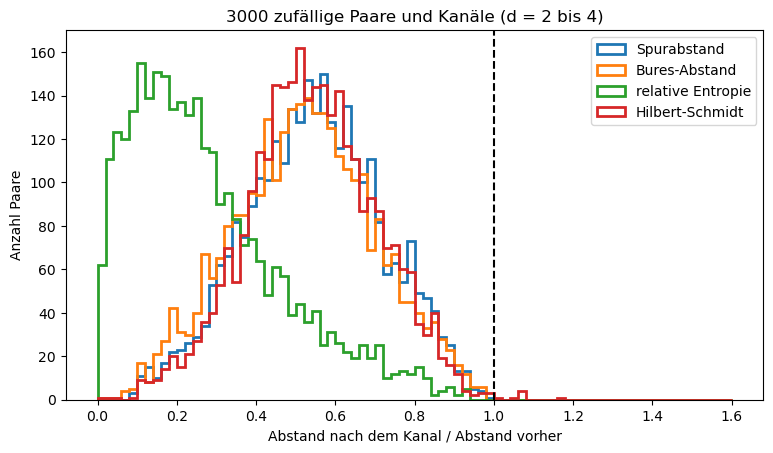

In [24]:
information.data_processing()

**24. Unterscheiden mit vielen Kopien: der Chernoff-Exponent**

Mit n Kopien fällt der kleinste Fehler exponentiell; die Rate ist der Chernoff-Exponent ξ. Für große n nutzt der Code die Symmetrie der Kopien (Schur-Weyl), statt Matrizen der Dimension 2ⁿ aufzustellen.

Der Exponent pro Kopie fällt von 0.18 bei 10 Kopien auf 0.056 bei 400 und nähert sich langsam ξ = 0.048. Der Spurabstand einer einzelnen Kopie (0.29) bestimmt diesen Exponenten nicht; bei vielen Kopien zählt eine andere Größe.

T = 0.2915, F = 0.9150, Chernoff: Q = 0.9529 bei s = 0.499, ξ = 0.0482
zum Vergleich: −ln F = 0.0889, D(ρ‖σ) = 0.1946 nat, D(σ‖ρ) = 0.1964 nat
n = 2: direkt 0.334074137354, Blöcke 0.334074137354
n = 5: direkt 0.236034079366, Blöcke 0.236034079366
n = 8: direkt 0.185329573846, Blöcke 0.185329573846


−(1/n) ln P_err: n = 10 → 0.1842, n = 100 → 0.0705, n = 400 → 0.0556; ξ = 0.0482


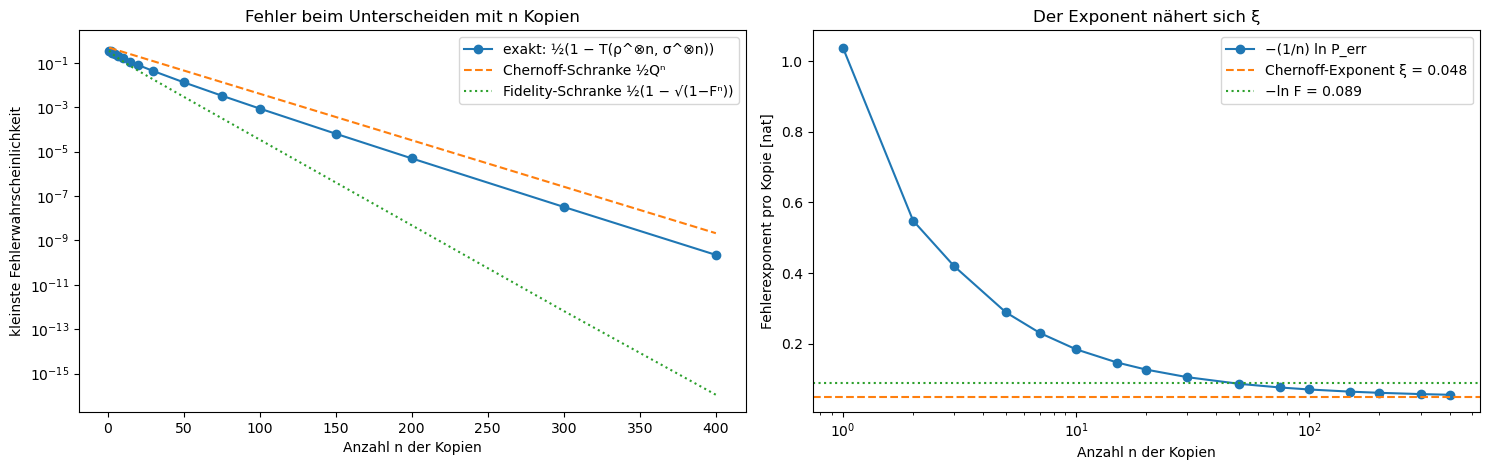

In [25]:
information.chernoff()

**25. Entropien**

Die Rényi-Entropien einer Familie von Spektren, die bedingte Entropie zweier Qubits und die starke Subadditivität dreier Qubits an Zufallszuständen.

Die Rényi-Entropie fällt mit ihrem Parameter; die von-Neumann-Entropie ist der Fall α = 1. Die bedingte Entropie kann negativ werden, bis −1 Bit beim Bell-Zustand, was klassisch unmöglich ist; Zustände vollen Rangs sind meist positiv. Starke Subadditivität und Araki-Lieb gelten für alle 3000 Zufallszustände.

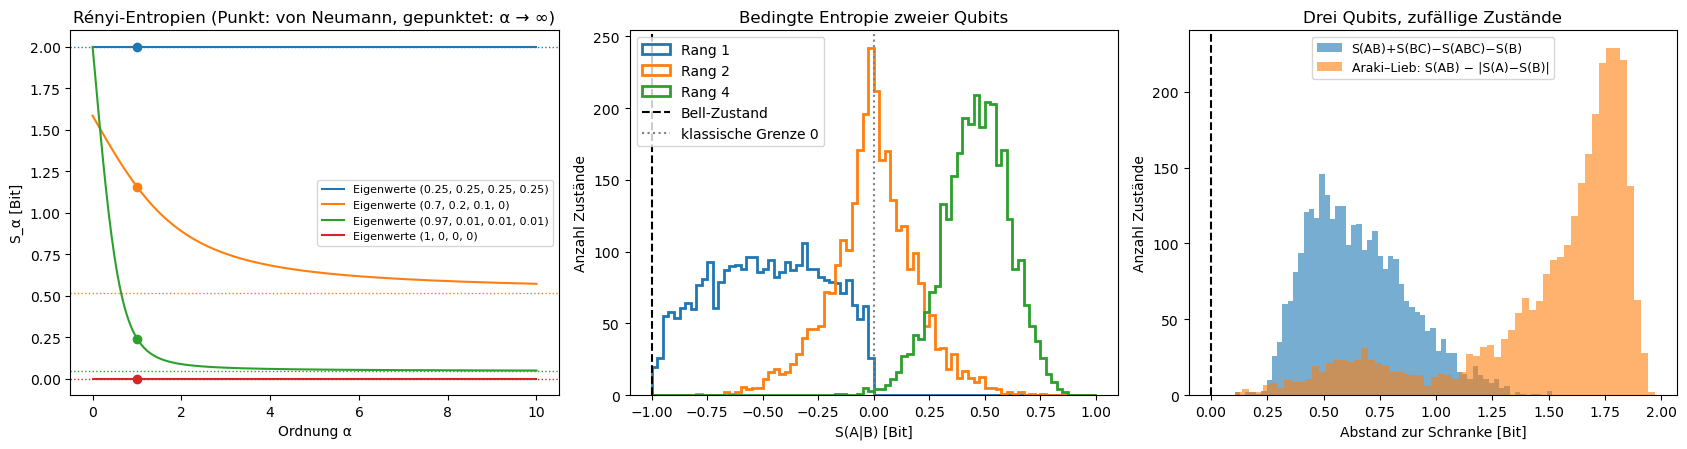

kleinster Wert: starke Subadditivität 1.06e-01, Araki–Lieb 1.06e-01


In [26]:
information.entropies()

**26. Schumacher-Kompression**

Wie viele Qubits braucht man, um n Kopien eines Zustands bis auf einen Fehler ε zu speichern? Nach Schumacher genügen für große n S(ρ) Qubits pro Kopie.

Für einen Zustand mit S = 0.469 Bit braucht man bei 10 000 Kopien 0.480 Qubits pro Kopie (ε = 0.1) oder 0.490 (ε = 0.01). Die Annäherung an S ist langsam, etwa wie 1/√n: Das ist die operative Bedeutung der von-Neumann-Entropie.

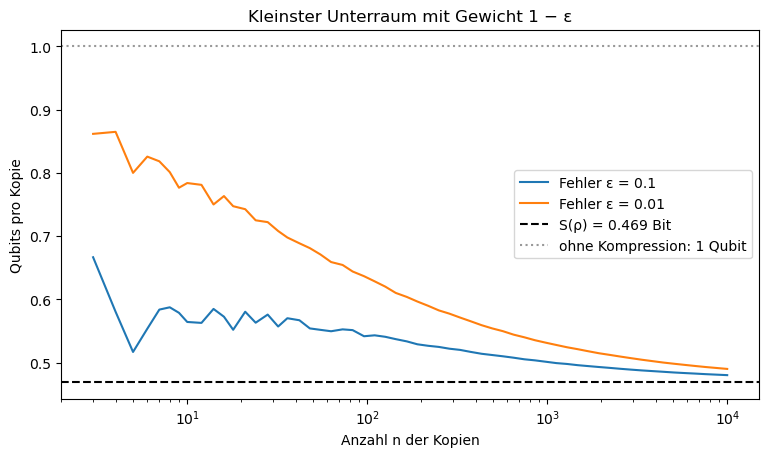

n = 12, ε = 0.01: direkt 0.7811 Qubits pro Kopie, Formel 0.7811
n = 10 000: ε = 0.1 → 0.4803, ε = 0.01 → 0.4902 (S = 0.4690)


In [27]:
information.schumacher()

**27. Holevo-Schranke und Accessible Information**

Wie viel klassische Information lässt sich aus Quantenzuständen auslesen? Die Holevo-Größe χ ist die obere Grenze; die Accessible Information ist das, was die beste Messung tatsächlich herausholt.

Selbst die beste Messung erreicht χ nicht. Bei der Trine bringt die beste Messung 0.585 Bit (log₂3 − 1), die Trine-Messung selbst nur 0.333 Bit; beim Tetraeder sind es 0.415 gegen 0.208 Bit. Die beste Messung ist dabei weder projektiv noch die naheliegende.

Trine    : chi 1.0000, eigene 0.3333, anti 0.5850, numerisch 0.5850


Tetraeder: chi 1.0000, eigene 0.2075, anti 0.4150, numerisch 0.4150
Erwartet: Trine log₂3 − 1 = 0.5850, Tetraeder 2 − log₂3 = 0.4150


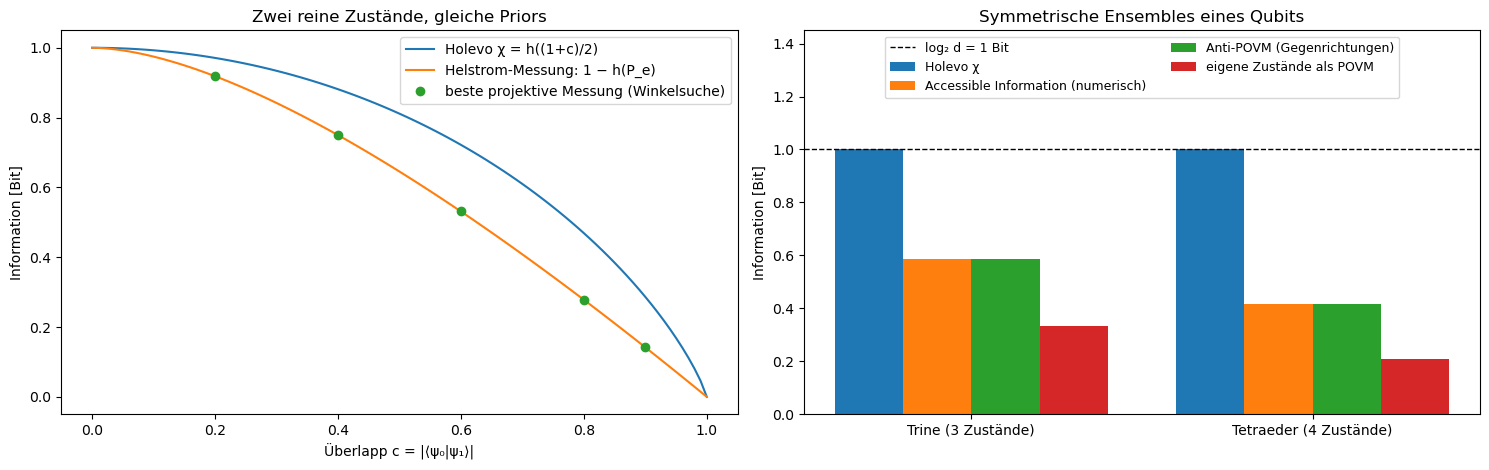

In [28]:
information.holevo_bound()

**28. No-Cloning und No-Signalling**

Ein unbekannter Zustand lässt sich nicht kopieren. Die beste universelle Klonmaschine (Bužek-Hillery) macht zwei unvollkommene Kopien; dazu die Prüfung, dass Alice mit einer lokalen Operation kein Signal an Bob sendet.

Bužek-Hillery gibt jeder Kopie die Fidelity ⅚, für jeden Eingang; die naive CNOT-Kopie im Mittel nur ⅔, so viel wie Messen und neu Präparieren. Alices Kanal ändert Bobs Zustand nicht (Abweichung 10⁻¹⁶); erst mit Alices Messergebnis wüsste Bob mehr.

Isometrie V†V = I: True
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Kopie 1 = Kopie 2 = (2/3)ψ + (1/6)I: True, F = 0.8333
Mittel über die Kugel: Bužek–Hillery 0.8333, CNOT-Kopie 0.6667


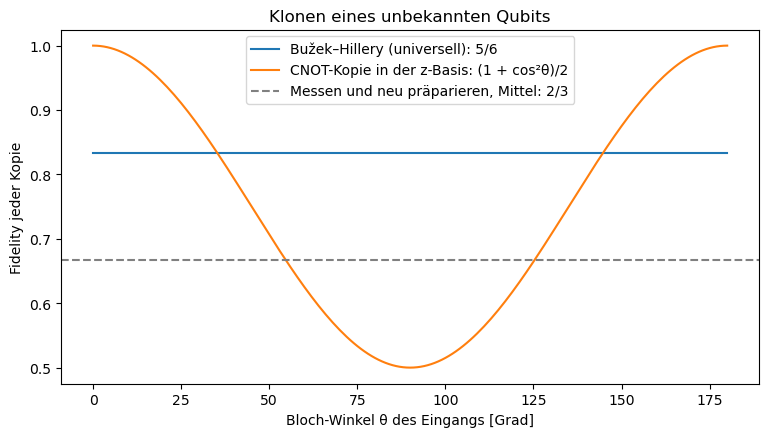

Bob nach Alices Kanal: Spurabstand zu vorher 3.1e-16
Alice misst σ_z: Bobs bedingter Zustand (Ergebnis 0) weicht um T = 0.271 ab, das Mittel über beide Ergebnisse um 0.0e+00


In [29]:
information.no_cloning()

**29. Quanten-Fisher-Information**

Die Quanten-Fisher-Information F_Q begrenzt, wie genau sich ein Phasenwinkel schätzen lässt. N unabhängige Qubits geben F_Q = N (Standard-Quantenlimit), ein verschränkter GHZ-Zustand N² (Heisenberg-Limit).

Ohne Rauschen wächst GHZ wie N² (64 bei 8 Qubits), der Produktzustand wie N. Mit 5 % Dephasierung flacht GHZ ab (11.9 bei 8 Qubits) und verliert nach der Formel ab 14 Qubits gegen den Produktzustand: Verschränkung hilft nur, solange das Rauschen klein ist.

Produkt  p = 0.0: F_Q exakt [1. 2. 3. 4. 5. 6. 7. 8.]; größte Abweichung Bures 1.5e-03
GHZ      p = 0.0: F_Q exakt [ 1.  4.  9. 16. 25. 36. 49. 64.]; größte Abweichung Bures 3.4e-02


Produkt  p = 0.05: F_Q exakt [0.81 1.62 2.43 3.24 4.05 4.86 5.67 6.48]; größte Abweichung Bures 1.0e-03


GHZ      p = 0.05: F_Q exakt [ 0.81   2.624  4.783  6.887  8.717 10.167 11.21  11.859]; größte Abweichung Bures 2.2e-02


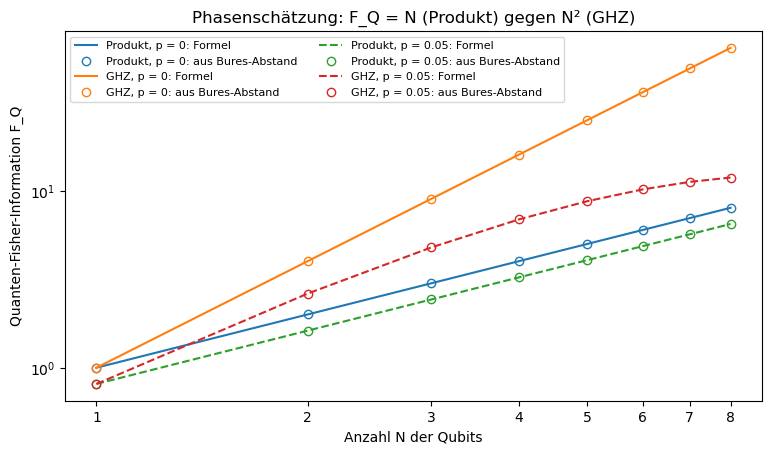

In [30]:
information.fisher()

**30. Abstände zwischen Kanälen: Diamantnorm gegen mittlere Fidelity**

Die Diamantnorm misst den schlimmsten Fall, auch mit einem Hilfssystem, und wird als SDP berechnet; die mittlere Fehlerrate r misst den Durchschnitt, wie Randomized Benchmarking.

Bei Depolarisation ist die Diamantnorm 3r/2, bei kohärenter Überrotation aber √(3r/2). Bei r = 10⁻⁴ ist sie für die Überrotation 1.2·10⁻², hundertmal größer als für Depolarisation: Kohärente Fehler sind viel gefährlicher, als die mittlere Fidelity zeigt. Ein Hilfssystem kann den Abstand vergrößern.

Überrotation ε = 0.2: SDP 0.09983, ohne Ancilla 0.09980, sin(ε/2) = 0.09983
Depolarisation p = 0.1: SDP 0.07500 (3p/4 = 0.075), ohne Ancilla 0.05000 (p/2 = 0.05)


Überrotation (kohärent) : r = 1e-4 → ½‖·‖◇ ≈ 1.22e-02
Depolarisation          : r = 1e-4 → ½‖·‖◇ ≈ 1.50e-04
Amplitudendämpfung      : r = 1e-4 → ½‖·‖◇ ≈ 3.00e-04


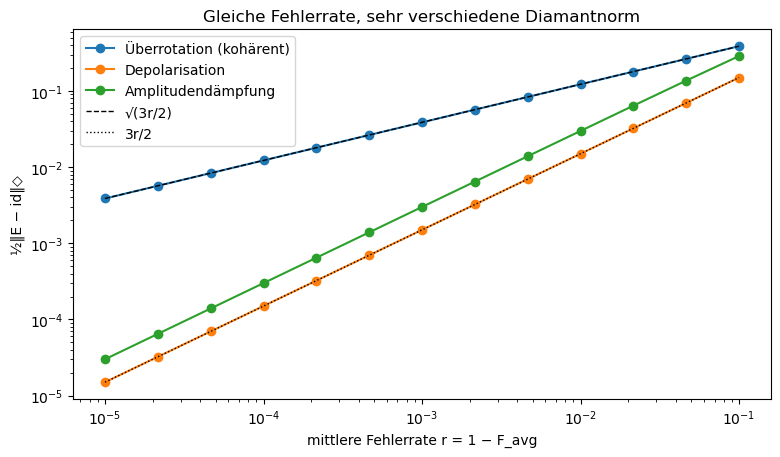

In [31]:
information.channel_distances()

**31. Kanalkapazitäten**

Wie viel klassische Information (C), mit Verschränkung (C_E) und wie viel Quanteninformation (Q) ein Kanal pro Nutzung überträgt, für den depolarisierenden Kanal und die Amplitudendämpfung.

C_E liegt über C, bis zum Doppelten. Beim depolarisierenden Kanal mit p = 0.1 ist C = 0.71 Bit und C_E = 1.50 Bit; die Quantenkapazität ist ab p = ⅓ null, zwischen 0.25 und ⅓ unbekannt. Bei der Amplitudendämpfung ist Q ab γ = ½ null, weil der Kanal dort antidegradierbar wird.

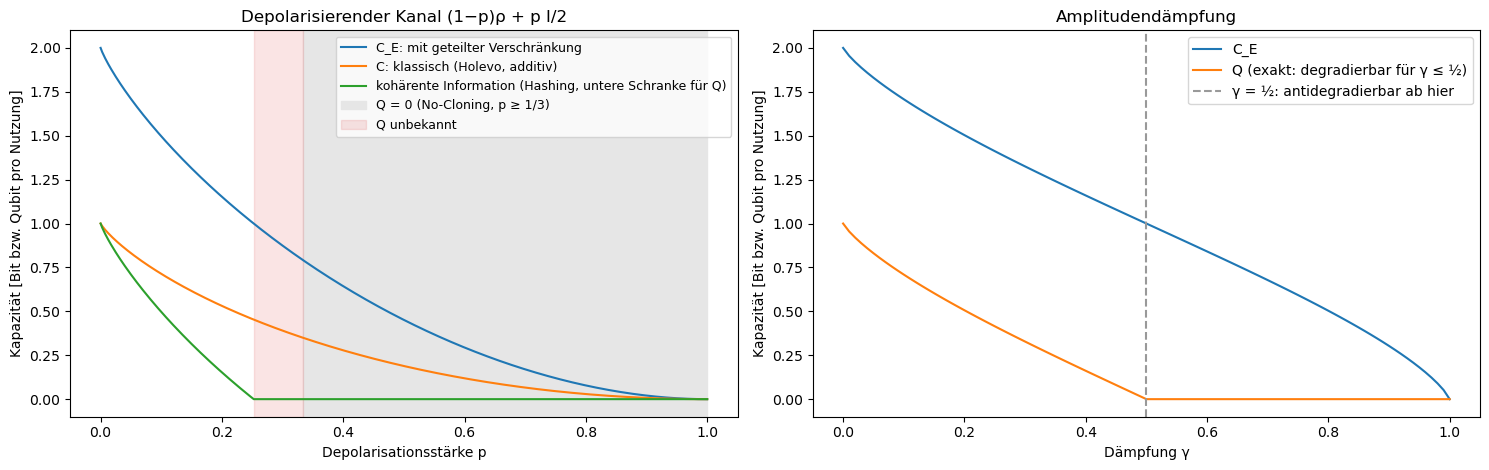

Hashing-Schranke wird null bei p ≈ 0.253; zwischen 0.253 und 1/3 ist Q nicht bekannt.
Bei p = 0.1: C = 0.714, C_E = 1.497, kohärente Information = 0.497
Amplitudendämpfung γ = 0.2: Q = 0.506, C_E = 1.503; γ = 0.6: Q = 0.000


In [32]:
information.capacities()